# Lab01 - sprint 2

В первом спринте мы показали, что величина X1 (интенсивность рамановского сигнала на 500.33 см⁻¹) хорошо описывается нормальным распределением: асимметрия = 0.048, эксцесс -0.353, критерий Шапиро-Уилка подтвердил нормальность (p≈0.071).

Поэтому этом спринте мы построим два датчика нормальных случайных чисел и настроим их на X1. Каждый датчик реализован по своей статье-первоисточнику:

| № | Метод | Первоисточник |
|---|-------|---------------|
| 1 | Полярный метод (метод полярных координат) | Marsaglia G., Bray T. A. *A Convenient Method for Generating Normal Variables* // SIAM Review. 1964. Vol. 6, № 3. P. 260–264. doi:10.1137/1006063 |
| 2 | Метод отношений равномерных величин (ratio-of-uniforms) | Kinderman A. J., Monahan J. F. *Computer Generation of Random Variables Using the Ratio of Uniform Deviates* // ACM Transactions on Mathematical Software. 1977. Vol. 3, № 3. P. 257–260. doi:10.1145/355744.355750 |

Общая схема работы обоих датчиков:

```
вихрь Мерсенна  →  U(0,1)  →  [метод из статьи]  →  Z ~ N(0,1)  →  X = μ + σ·Z  ≈  X1
```

*Что мы проверяем для каждого датчика:*
1. Код из статьи реализован правильно (пошаговая и быстрая версии выдают одни и те же числа).
2. Датчик действительно выдаёт N(0,1) - сравнение с теоретической базой на достаточно большой выборке.
3. Сгенерированные значения похожи на реальные X1 - сравним метрики и критерии согласия. Насколько сгенерированные числа соответствуют нормальному распределению?

## Подготовка: данные X1 и приведение к стандартному нормальному

In [2]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

# Загружаем данные так же, как в спринте 1
base_url = "https://raw.githubusercontent.com/Alvaro-FG/Raman_Sugars/main/"
spectra = pd.read_csv(base_url + "Sugar_Concentration_Test_ALL_spectra.csv")

# Ищем ближайшую к 500 см⁻¹ точку спектра
wavenumbers = spectra["Wavenumber [cm-1]"].to_numpy()
idx_500 = np.abs(wavenumbers - 500).argmin()

# Строка спектра = одна частота, столбцы = измерения. Берём строку и превращаем в вектор
X1 = spectra.iloc[idx_500, 1:].astype(float).to_numpy()

mu_hat = X1.mean()           # оценка мат. ожидания
sigma_hat = X1.std(ddof=1)   # несмещённая оценка стандартного отклонения
N_REAL = len(X1)

print(f"Частота: {wavenumbers[idx_500]:.2f} см⁻¹")
print(f"Число измерений: {N_REAL}")
print(f"Оценка μ = {mu_hat:.3f}")
print(f"Оценка σ = {sigma_hat:.3f}")

Частота: 500.33 см⁻¹
Число измерений: 1960
Оценка μ = 3550.865
Оценка σ = 428.902


Оба метода из статей генерируют числа из **стандартного** нормального распределения N(0, 1). Это удобно, т.к. у нормального распределения есть свойство линейности:

$$Z \sim N(0,1) \;\Rightarrow\; X = \mu + \sigma Z \sim N(\mu, \sigma^2).$$

Проверим: $E[X] = \mu + \sigma E[Z] = \mu$, $D[X] = \sigma^2 D[Z] = \sigma^2$

Линейное преобразование не меняет форму нормального распределения, а лишь смещает его центр и растягивает/сжимает сам график плотности.

Значит, достаточно один раз написать хороший датчик N(0,1), а затем подставить оценки $\hat\mu$, $\hat\sigma$, полученные по X1. Обратное преобразование $Z = (X - \hat\mu)/\hat\sigma$ - это та же стандартизация, которую мы делали в спринте 1 через `StandardScaler`.

### Источник равномерных чисел: вихрь Мерсенна

Оба метода - это **преобразования** равномерных случайных чисел U(0,1) в нормальные. Значит, нужен базовый датчик равномерных чисел. Мы возьмём вихрь Мерсенна MT19937 (Matsumoto, Nishimura, 1998). Его период = $2^{19937}-1$, и он проходит стандартные тесты равномерности, поэтому качество наших нормальных чисел будет определяться исключительно методом из статьи.

Обернём MT19937 в маленький класс, который считает, сколько равномерных чисел потрачено. Это нужно, чтобы потом сравнить, насколько рационально использование обоих методов.

In [3]:
class UniformSource:
    """Источник U[0,1) на основе вихря Мерсенна (MT19937) со счётчиком."""

    def __init__(self, seed):
        self.rng = np.random.Generator(np.random.MT19937(seed))
        self.used = 0  # сколько равномерных чисел уже выдали

    def one(self):
        """Одно число U[0,1) — для пошаговых версий алгоритмов."""
        self.used += 1
        return self.rng.random()

    def many(self, shape):
        """Массив чисел U[0,1) — для быстрых (векторных) версий."""
        arr = self.rng.random(shape)
        self.used += arr.size
        return arr

# Быстрая проверка: равномерные числа на самом деле равномерные
u_check = UniformSource(seed=1).many(100_000)
print("Среднее (теория 0.5):    ", round(u_check.mean(), 4))
print("Дисперсия (теория 1/12 ≈ 0.0833):", round(u_check.var(), 4))
print("Тест Колмогорова против U(0,1): p =", round(stats.kstest(u_check, "uniform").pvalue, 3))

Среднее (теория 0.5):     0.4998
Дисперсия (теория 1/12 ≈ 0.0833): 0.0834
Тест Колмогорова против U(0,1): p = 0.96


### Общие функции для проверок

Чтобы сравнивать реальные данные и датчики одинаково, заведём одну функцию с метриками. Набор метрик тот же, что в спринте 1: среднее, стандартное отклонение, асимметрия, эксцесс, квантили.

In [4]:
def metrics(sample):
    """Набор описательных статистик выборки."""
    sample = np.asarray(sample)
    return {
        "n": len(sample),
        "mean": sample.mean(),
        "std": sample.std(ddof=1),
        "skew": stats.skew(sample),
        "kurt (excess)": stats.kurtosis(sample),   # у нормального = 0
        "q05": np.quantile(sample, 0.05),
        "q25": np.quantile(sample, 0.25),
        "median": np.median(sample),
        "q75": np.quantile(sample, 0.75),
        "q95": np.quantile(sample, 0.95),
    }


def check_standard_normal(z, name):
    """Сравнение выборки с ТЕОРЕТИЧЕСКИМ N(0,1): проверяем сам датчик."""
    m = metrics(z)
    ks = stats.kstest(z, "norm")                 # критерий Колмогорова
    sw = stats.shapiro(z[:5000])                 # Шапиро–Уилк (на первых 5000)
    theory = {"mean": 0, "std": 1, "skew": 0, "kurt (excess)": 0,
              "q05": stats.norm.ppf(0.05), "q25": stats.norm.ppf(0.25),
              "median": 0, "q75": stats.norm.ppf(0.75), "q95": stats.norm.ppf(0.95)}
    table = pd.DataFrame({"датчик": {k: m[k] for k in theory}, "теория N(0,1)": theory})
    table["разница"] = table["датчик"] - table["теория N(0,1)"]
    print(f"=== {name}: сравнение с N(0,1), n = {len(z)} ===")
    print(table.round(4))
    print(f"\nКолмогоров:   D = {ks.statistic:.4f}, p = {ks.pvalue:.3f}")
    print(f"Шапиро–Уилк:  W = {sw.statistic:.4f}, p = {sw.pvalue:.3f}")
    return ks.pvalue, sw.pvalue


def compare_with_real(real, generated, name):
    """Сравнение сгенерированных значений с реальными значениями переменной X1."""
    table = pd.DataFrame({"X1 (реальные)": metrics(real), name: metrics(generated)})
    table["разница, %"] = (table[name] - table["X1 (реальные)"]) / table["X1 (реальные)"].abs() * 100
    print(table.round(3))
    ks2 = stats.ks_2samp(real, generated)        # двухвыборочный Колмогоров–Смирнов
    print(f"\nДвухвыборочный Колмогоров–Смирнов: D = {ks2.statistic:.4f}, p = {ks2.pvalue:.3f}")
    return ks2.pvalue


def plot_vs_real(real, generated, name):
    """Гистограммы и Q-Q график: реальные X1 против сгенерированных значений."""
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
    bins = np.linspace(min(real.min(), generated.min()), max(real.max(), generated.max()), 35)
    axes[0].hist(real, bins=bins, density=True, alpha=0.55, edgecolor="black", label="X1 реальные")
    axes[0].hist(generated, bins=bins, density=True, alpha=0.55, edgecolor="black", label=name)
    axes[0].set_title("Гистограммы плотности")
    axes[0].set_xlabel("Интенсивность")
    axes[0].legend()

    # Если распределения совпадают, точки лежат на диагонали.
    q = np.linspace(0.005, 0.995, 200)
    axes[1].scatter(np.quantile(real, q), np.quantile(generated, q), s=12)
    lim = [bins[0], bins[-1]]
    axes[1].plot(lim, lim, "r--", label="y = x")
    axes[1].set_title("Q-Q: реальные vs сгенерированные")
    axes[1].set_xlabel("Квантили X1")
    axes[1].set_ylabel(f"Квантили: {name}")
    axes[1].legend()
    plt.tight_layout()
    plt.show()

## Random 01 - Полярный метод Марсальи-Брэя

### Описание

**Используемая статья:** Marsaglia G., Bray T. A. *A Convenient Method for Generating Normal Variables* // SIAM Review. 1964. Vol. 6, № 3. P. 260–264. doi:10.1137/1006063.

**Идея метода:** Исторически раньше появилось преобразование Бокса-Мюллера (1958): из двух равномерных чисел $U_1, U_2$ получают две нормальные

$$Z_1 = \sqrt{-2\ln U_1}\cos(2\pi U_2), \qquad Z_2 = \sqrt{-2\ln U_1}\sin(2\pi U_2).$$

У него есть практический недостаток: на каждую пару нужно вычислить $\cos$ и $\sin$, а это дорогие операции по сравнению, например с просто сложением. Марсалья и Брэй предложили получать «случайный угол» без тригонометрии: для этого надо взять случайную точку в квадрате $[-1,1]^2$ и оставить её, только если она попала внутрь единичного круга. Тогда $\cos\theta = V_1/\sqrt{S}$ и $\sin\theta = V_2/\sqrt{S}$, где $S = V_1^2+V_2^2$, - синус и косинус получаются из координат точки, и, получается, их самих рассчитывать уже не нужно, что экономит время и ресурсы.

**Где используется:** Полярный метод - стандартный способ генерации нормальных чисел во многих библиотеках, например, `std::normal_distribution` в libstdc++ (GCC) реализован именно им.

**Сильные стороны метода:** простой, точный (не приближённый), нет $\sin/\cos$, за один удачный шаг он выдаёт сразу две независимые нормальные величины.
**Слабые стороны метода:** есть отбраковка (около 21.5% точек выбрасываются), поэтому число итераций случайно; всё ещё нужны операции $\ln$ и $\sqrt{}$.

### Математическое описание

**Алгоритм согласно статье:**
1. Сгенерировать $U_1, U_2 \sim U(0,1)$ и положить $V_1 = 2U_1 - 1$, $V_2 = 2U_2 - 1$ (точка в квадрате $[-1,1]^2$).
2. Вычислить $S = V_1^2 + V_2^2$. Если $S \ge 1$ или $S = 0$, затем вернуться к шагу 1.
3. Вернуть $Z_1 = V_1\sqrt{\dfrac{-2\ln S}{S}}, \quad Z_2 = V_2\sqrt{\dfrac{-2\ln S}{S}}.$

*Шаг А. Берём точку, равномерную в круге - это такой круг, вероятность попадания в определённую область которого пропорциональна площади этой области.* После отбраковки точка $(V_1, V_2)$ равномерно распределена в единичном круге (мы просто типа «отрезаем» лишнее от равномерного квадрата). Итого вероятность принятия = площадь круга / площадь квадрата $= \pi/4 \approx 0.785$.

*Шаг Б. $S$ равномерна на (0,1), угол равномерен, и они независимы.* Пусть $\theta$ - полярный угол точки. Вероятность того, что точка попала в круг радиуса $\sqrt{s}$:
$$P(S \le s) = \frac{\pi (\sqrt{s})^2}{\pi} = s, \quad 0<s<1,$$
то есть $S \sim U(0,1)$. По симметрии круга угол $\theta \sim U(0, 2\pi)$ и не зависит от расстояния до центра.

*Шаг В. Радиус $R = \sqrt{-2\ln S}$ имеет распределение Рэлея (непрерывное вероятностное распределение, которое описывает длину (или модуль) двумерного вектора, если его координаты
X и Y являются независимыми нормально распределенными случайными величинами с нулевым средним и одинаковой дисперсией).*
$$P(R > r) = P(-2\ln S > r^2) = P(S < e^{-r^2/2}) = e^{-r^2/2}.$$
что эквивалентно $R^2 \sim \chi^2_2$ (экспоненциальное с параметром 1/2).

*Шаг Г. Пара независимых N(0,1) в полярных координатах.* Совместная плотность двух независимых $N(0,1)$:
$$f(z_1, z_2) = \frac{1}{2\pi} e^{-(z_1^2+z_2^2)/2}.$$
Переходим к полярным координатам $z_1 = r\cos\theta$, $z_2 = r\sin\theta$ (якобиан равен $r$):
$$f(r, \theta) = \underbrace{\frac{1}{2\pi}}_{\theta \sim U(0,2\pi)} \cdot \underbrace{r e^{-r^2/2}}_{R \sim \text{Рэлей}}.$$
Плотность распалась на произведение - значит, пара нормальных величин = **независимые** равномерный угол и рэлеевский радиус. Ровно это мы и построили в шагах Б–В.

*Шаг Д.* $\cos\theta = V_1/\sqrt S$, $\sin\theta = V_2/\sqrt S$, поэтому
$$Z_1 = R\cos\theta = \sqrt{-2\ln S}\cdot\frac{V_1}{\sqrt S} = V_1\sqrt{\frac{-2\ln S}{S}},$$
и аналогично для $Z_2$. Из одной и той же точки мы использовали $S$ (для радиуса) и направление (для угла) - по шагу Б они независимы, поэтому повторного использования случайности тут нет.

**Затраты метода:** Среднее число попыток на одну пару такое: $= 4/\pi \approx 1.273$, каждая попытка тратит 2 равномерных числа. Значит, на одно нормальное число уходит в среднем $\dfrac{2 \cdot 4/\pi}{2} = 4/\pi \approx 1.273$ равномерных. Это мы дальше проверим эмпирически.

### Код
Мы выбрали итеративный подход, поэтому сделаем 2 версии:

* **v1 - пошаговая**, один в один по тексту статьи, через обычный цикл `while`. Её легко читать и сверять с алгоритмом, но она медленная.
* **v2 - векторная**: генерируем сразу много точек numpy-массивом, отбрасываем лишние маской. Математическая база тут останется прежней, но время должно значительно сократиться.

Векторный подход v2 берёт из вихря Мерсенна числа в том же порядке, что и v1 (пары $U_1, U_2$ подряд). Поэтому при одинаковом seed обе версии должны выдать одни и те же числа - так проверяется, что при ускорении мы ничего не сломали.

In [5]:
def polar_v1(n, uniform):
    """Полярный метод, пошаговая версия (Marsaglia & Bray, 1964)."""
    result = []
    while len(result) < n:
        # Шаг 1: случайная точка в квадрате [-1, 1] x [-1, 1]
        v1 = 2.0 * uniform.one() - 1.0
        v2 = 2.0 * uniform.one() - 1.0
        # Шаг 2: квадрат расстояния до центра; оставляем только точки внутри круга
        s = v1 * v1 + v2 * v2
        if s >= 1.0 or s == 0.0:
            continue                      # отбраковка, пробуем снова
        # Шаг 3: множитель sqrt(-2 ln S / S) превращает точку в пару N(0,1)
        factor = np.sqrt(-2.0 * np.log(s) / s)
        result.append(v1 * factor)
        result.append(v2 * factor)
    return np.array(result[:n])


def polar_v2(n, uniform, batch=None, stats_out=None):
    """Полярный метод, векторная версия. Та же математика, что в v1."""
    out = []
    got = attempts = accepted = 0
    while got < n:
        # Сколько точек брать за раз: нужно (n - got)/2 пар, делим на P(принятия)=pi/4
        # и берём с запасом 10%, чтобы почти всегда хватало одного прохода
        k = batch or int((n - got) / 2 / (np.pi / 4) * 1.1) + 10
        u = uniform.many((k, 2))          # k пар (U1, U2) в том же порядке, что и в v1
        v = 2.0 * u - 1.0
        s = (v ** 2).sum(axis=1)
        ok = (s < 1.0) & (s > 0.0)        # маска принятых точек
        attempts += k
        accepted += ok.sum()
        v, s = v[ok], s[ok]
        factor = np.sqrt(-2.0 * np.log(s) / s)
        z = (v * factor[:, None]).ravel() # [z1, z2, z1, z2, ...] - это остаётся из v1
        out.append(z)
        got += len(z)
    if stats_out is not None:
        stats_out.update(attempts=attempts, accepted=accepted)
    return np.concatenate(out)[:n]


def polar_normal(n, mu=0.0, sigma=1.0, seed=None):
    """Датчик N(mu, sigma^2) на основе полярного метода: X = mu + sigma * Z."""
    return mu + sigma * polar_v2(n, UniformSource(seed))

### Тесты

**Тест 1. v1 и v2 выдают одинаковые числа.**

In [6]:
z_v1 = polar_v1(2000, UniformSource(seed=7))
z_v2 = polar_v2(2000, UniformSource(seed=7))
print("Максимальное расхождение v1 и v2:", np.abs(z_v1 - z_v2).max())

n_speed = 200_000
t0 = time.perf_counter(); polar_v1(n_speed, UniformSource(1)); t_v1 = time.perf_counter() - t0
t0 = time.perf_counter(); polar_v2(n_speed, UniformSource(1)); t_v2 = time.perf_counter() - t0
print(f"Время на {n_speed} чисел: v1 = {t_v1:.3f} c, v2 = {t_v2:.4f} c, ускорение ≈ {t_v1 / t_v2:.0f} раз")

Максимальное расхождение v1 и v2: 0.0
Время на 200000 чисел: v1 = 0.238 c, v2 = 0.0168 c, ускорение ≈ 14 раз


Расхождение равно нулю (или порядка $10^{-16}$ - ошибка округления), значит векторная версия реализует ровно тот же алгоритм. Дальше пользуемся быстрой v2.

**Тест 2. Доля принятых точек и расход равномерных чисел совпадают с теорией.** Теория: $P(\text{принятия}) = \pi/4 \approx 0.7854$, равномерных на одно нормальное $= 4/\pi \approx 1.2732$.

In [9]:
n_big = 1_000_000
info_polar = {}
z_polar = polar_v2(n_big, UniformSource(seed=2026), stats_out=info_polar)

# Доля принятия = принятые точки / все сгенерированные точки
acceptance = info_polar["accepted"] / info_polar["attempts"]
# Каждая точка тратит 2 равномерных числа, каждая принятая точка даёт 2 нормальных
uniform_per_normal = (2 * info_polar["attempts"]) / (2 * info_polar["accepted"])

print(f"Доля принятых точек:   эмпирически {acceptance:.4f}, теория π/4 = {np.pi / 4:.4f}")
print(f"Равномерных на 1 норм.: эмпирически {uniform_per_normal:.4f}, теория 4/π = {4 / np.pi:.4f}")

Доля принятых точек:   эмпирически 0.7857, теория π/4 = 0.7854
Равномерных на 1 норм.: эмпирически 1.2728, теория 4/π = 1.2732


**Тест 3. Датчик выдаёт N(0,1): сравнение с теоретическими значениями на 1 000 000 чисел.**

In [10]:
check_standard_normal(z_polar, "Полярный метод")

=== Полярный метод: сравнение с N(0,1), n = 1000000 ===
               датчик  теория N(0,1)  разница
mean          -0.0014         0.0000  -0.0014
std            1.0004         1.0000   0.0004
skew          -0.0022         0.0000  -0.0022
kurt (excess) -0.0013         0.0000  -0.0013
q05           -1.6484        -1.6449  -0.0035
q25           -0.6753        -0.6745  -0.0008
median        -0.0016         0.0000  -0.0016
q75            0.6743         0.6745  -0.0002
q95            1.6429         1.6449  -0.0020

Колмогоров:   D = 0.0008, p = 0.531
Шапиро–Уилк:  W = 0.9995, p = 0.237


(np.float64(0.5313838763439768), np.float64(0.23651340195263237))

При $n = 10^6$ стандартная ошибка среднего равна $1/\sqrt{n} = 0.001$, поэтому отклонения среднего порядка тысячных — это нормально. Асимметрия и эксцесс у N(0,1) равны нулю, у датчика они тоже должны быть около нуля. Большие p-value у критериев означают, что отличий от N(0,1) не обнаружено даже на миллионе чисел.

**Тест 4. $Z_1$ и $Z_2$ из одной пары независимы.** Статья утверждает, что две величины, полученные из одной точки, независимы. Проверим корреляцию Пирсона (линейная связь) и корреляцию квадратов (нелинейная связь: если бы $|Z_1|$ и $|Z_2|$ были связаны через общий радиус, это было бы видно здесь).

corr(Z1, Z2)     = -0.00037, p = 0.793
corr(Z1², Z2²)   = +0.00151, p = 0.285


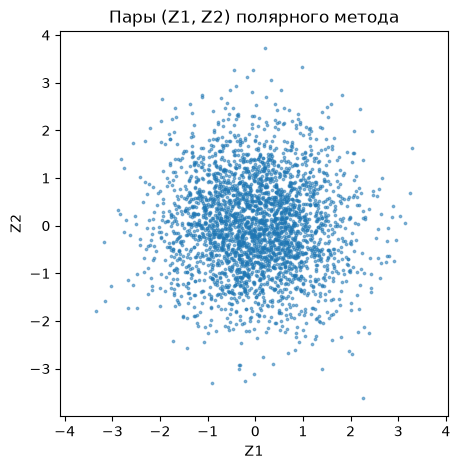

In [11]:
z1, z2 = z_polar[0::2], z_polar[1::2]     # чётные - Z1, нечётные - Z2 из той же пары

r_lin, p_lin = stats.pearsonr(z1, z2)
r_sq, p_sq = stats.pearsonr(z1 ** 2, z2 ** 2)
print(f"corr(Z1, Z2)     = {r_lin:+.5f}, p = {p_lin:.3f}")
print(f"corr(Z1², Z2²)   = {r_sq:+.5f}, p = {p_sq:.3f}")

plt.figure(figsize=(5, 5))
plt.scatter(z1[:3000], z2[:3000], s=3, alpha=0.5)
plt.title("Пары (Z1, Z2) полярного метода")
plt.xlabel("Z1"); plt.ylabel("Z2"); plt.axis("equal")
plt.show()

Облако точек круглое, а обе корреляции близки к нулю. Для нормальных величин остутствие корреляции означает независимость, так что утверждение из статьи подтверждается.

**Тест 5. Сравнение датчика с реальными X1.** Генерируем столько же значений, сколько реальных измерений (1960), с параметрами $\hat\mu, \hat\sigma$ из данных.

               X1 (реальные)  Полярный метод  разница, %
n                   1960.000        1960.000       0.000
mean                3550.865        3561.212       0.291
std                  428.902         427.372      -0.357
skew                   0.047          -0.018    -138.159
kurt (excess)         -0.356          -0.037      89.632
q05                 2838.950        2847.746       0.310
q25                 3247.000        3278.453       0.969
median              3556.000        3558.762       0.078
q75                 3862.000        3858.299      -0.096
q95                 4237.000        4252.838       0.374

Двухвыборочный Колмогоров–Смирнов: D = 0.0281, p = 0.423


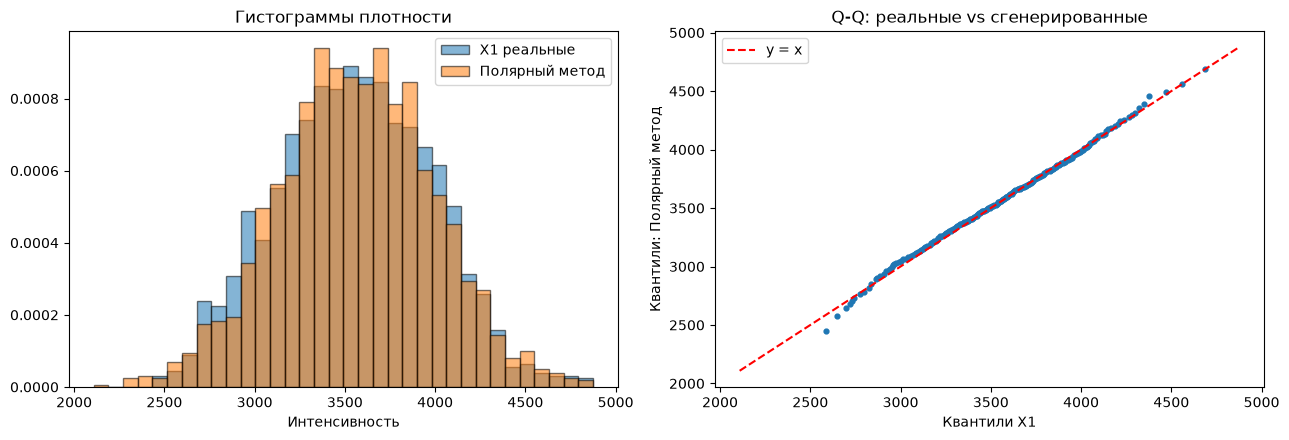

In [12]:
gen_polar = polar_normal(N_REAL, mu=mu_hat, sigma=sigma_hat, seed=42)
p_ks2_polar = compare_with_real(X1, gen_polar, "Полярный метод")
plot_vs_real(X1, gen_polar, "Полярный метод")

### Выводы

* Пошаговая реализация по статье и быстрая векторная версия дают одинаковые числа; векторная работает в десятки раз быстрее.
* Доля принятых точек и расход равномерных чисел совпали с теоретическими $\pi/4$ и $4/\pi$
* На миллионе чисел среднее, дисперсия, асимметрия, эксцесс и квантили совпадают с N(0,1), критерии Колмогорова и Шапиро–Уилка не отвергают нормальность распределения.
* $Z_1$ и $Z_2$ одной пары некоррелированы (в том числе их квадраты), то есть независимы.
* Среднее, стандартное отклонение и медиана сгенерированных значений совпадают с X1; двухвыборочный критерий Колмогорова–Смирнова сравнивает их с реальными данными. Самые заметные расхождения ожидаются в эксцессе и в хвостах (квантили 5% и 95%): в спринте 1 эксцесс X1 был −0.35, то есть хвосты реальных данных немного отличаются от нормальных.

## Random 02 - Метод отношений равномерных величин (Киндерман-Монахан)

### Описание

**Статья:** Kinderman A. J., Monahan J. F. *Computer Generation of Random Variables Using the Ratio of Uniform Deviates* // ACM Transactions on Mathematical Software. 1977. Vol. 3, № 3. P. 257–260. doi:10.1145/355744.355750.

**Идея метода:** Вместо полярных координат здесь предлагается выбирать случайную точку $(U, V)$ в специальной области $C$ на плоскости и возвращать **отношение** $X = V/U$. Область подобрана так, что это отношение имеет нужную плотность. Метод универсальный (подходит для многих распределений), а для нормального авторы дали готовый алгоритм с двумя «быстрыми» проверками, которые в большинстве случаев позволяют обойтись без логарифма.

Такой же алгоритм приведён у Кнута (Алгоритм R в разделе 3.4.1 второго тома «Искусства программирования»), а теория метода подробно разобрана у Деврая (Devroye, 1986, гл. IV.7).

**Сильные стороны метода:** достаточно простой код; общий принцип годится для любого распределения с ограниченными $f(x)$ и $x^2 f(x)$; благодаря «сжатиям» логарифм вычисляется редко; нет необходимости использовать тригонометрические функции или квадратный кореньна каждой итерации.

**Слабые стороны метода:** отбраковка чуть больше, чем у полярного метода (≈27% против ≈21.5%); за один шаг выдаётся одно число, а не два; для распределений с тяжёлыми хвостами рамка получается неэффективной.

Получается, что в теории мы могли бы применить этот метод для X2 из первого спринта (там распределение не прошло критерий Шапиро-Уилка о нормальности), например, но непонятно, насколько это было бы эффективно, т.к. там был тяжёлый правый хвост. Ну ладно.

### Математическое описание

**Теорема (Kinderman, Monahan, 1977).** Пусть $f(x) \ge 0$ — функция, пропорциональная нужной плотности, и
$$C = \{(u, v):\ 0 < u \le \sqrt{f(v/u)}\}.$$
Если точка $(U, V)$ равномерно распределена в $C$, то $X = V/U$ имеет плотность $f(x)/\int f$.

**Доказательство.** Плотность равномерной точки в $C$ равна $1/|C|$, где $|C|$ — площадь. Сделаем замену $(u, v) \to (u, x)$, где $x = v/u$, то есть $v = xu$. Якобиан:
$$\left|\frac{\partial(u,v)}{\partial(u,x)}\right| = \begin{vmatrix} 1 & 0 \\ x & u \end{vmatrix} = u.$$
Значит, совместная плотность $(U, X)$ равна $u/|C|$ при $0 < u \le \sqrt{f(x)}$. Интегрируем по $u$, чтобы найти плотность $X$:
$$p(x) = \frac{1}{|C|}\int_0^{\sqrt{f(x)}} u\,du = \frac{f(x)}{2|C|}.$$
Это пропорционально $f(x)$, что и требовалось. Заодно получили площадь области: $|C| = \tfrac12\int f(x)\,dx$.

**Применяем к нормальному распределению.** Берём $f(x) = e^{-x^2/2}$ (без нормирующего множителя). Условие попадания в $C$ таково:
$$u \le \sqrt{f(x)} = e^{-x^2/4} \iff \ln u \le -\frac{x^2}{4} \iff x^2 \le -4\ln u, \qquad x = v/u.$$

**Равномерный выбор точки в $C$.** Область $C$ может быть нестандартной формы, поэтому накрываем её прямоугольником и отбраковываем точки снаружи (метод Неймана):
* по $u$: $u \le \sqrt{f(x)} \le 1$, значит $0 < u \le 1$;
* по $v$: $|v| = |x|\,u \le |x| e^{-x^2/4}$. Максимум правой части находим через производную: $\frac{d}{dx}\left(x e^{-x^2/4}\right) = e^{-x^2/4}(1 - x^2/2) = 0 \Rightarrow x^2 = 2$, откуда $|v| \le \sqrt2\, e^{-1/2} = \sqrt{2/e} \approx 0.858$.

Прямоугольник: $u \in (0, 1]$, $v \in [-\sqrt{2/e},\ \sqrt{2/e}]$. Если $U_1, U_2 \sim U(0,1)$, то $v = \sqrt{2/e}\,(2U_2 - 1)$, и
$$X = \frac{v}{u} = \sqrt{8/e}\;\frac{U_2 - 1/2}{U_1}.$$

**Вероятность принятия** $= \dfrac{|C|}{\text{площадь прямоугольника}} = \dfrac{\tfrac12\sqrt{2\pi}}{2\sqrt{2/e}} = \dfrac{\sqrt{\pi e}}{4} \approx 0.7306.$
На одно нормальное число тратится в среднем $2/0.7306 \approx 2.737$ равномерных.

**«Сжатия» (squeeze) - главная практическая находка статьи.** Точная проверка $x^2 \le -4\ln u$ требует логарифма. Авторы окружают границу $-4\ln u$ двумя простыми функциями - одна всегда ниже, другая всегда выше:

* **Быстрое принятие:** Неравенство $\ln y \le y - 1$ при $y = c u$ даёт $-\ln u \ge \ln c + 1 - cu$. При $c = e^{1/4}$:
$$-4\ln u \ge 5 - 4e^{1/4}u.$$
Значит, если $x^2 \le 5 - 4e^{1/4}u$, то точно $x^2 \le -4\ln u$ - **принимаем без логарифма**.

* **Быстрый отказ:** Неравенство $\ln y \ge 1 - 1/y$ при $y = c u$ даёт $-\ln u \le \ln c - 1 + \frac{1}{cu}$. При $c = e^{1.35}$:
$$-4\ln u \le 1.4 + \frac{4e^{-1.35}}{u}.$$
Значит, если $x^2 \ge 1.4 + 4e^{-1.35}/u$, то точно $x^2 > -4\ln u$ - **отклоняем без логарифма**.

* Только если точка попала в узкую полосу между двумя границами, считаем $\ln u$.

**Итоговый алгоритм (алгоритм R из статьи Кнута):**
1. Сгенерировать $U_1, U_2 \sim U(0,1)$, положить $X = \sqrt{8/e}\,(U_2 - 1/2)/U_1$.
2. Если $X^2 \le 5 - 4e^{1/4}U_1$ - вернуть $X$.
3. Если $X^2 \ge 4e^{-1.35}/U_1 + 1.4$ - вернуться к шагу 1.
4. Если $X^2 \le -4\ln U_1$ — вернуть $X$, иначе вернуться к шагу 1.

Сжатия не меняют распределение результата, они лишь заранее отвечают на вопрос о том, попала ли точка в $C$. Это мы проверим потом с помощью отдельного теста.

Вихрь Мерсенна выдаёт числа из $[0, 1)$, а нам нужно $U_1 > 0$ ( так как мы потом на него делим и от него берём логарифм). Поэтому используем $U_1 = 1 - \text{random()} \in (0, 1]$, что тоже является равномерным распределением.

### Код

Снова две версии: **v1** - пошаговая, ровно по шагам 1–4; **v2** - векторная. Порядок потребления равномерных чисел одинаковый (пары $U_1, U_2$), поэтому при одном seed они должны совпасть. Дополнительно считаем, сколько раз пришлось вычислять логарифм, чтобы проверить, насколько полезны сжатия.

In [14]:
SQRT_8_E = np.sqrt(8.0 / np.e)        # ≈ 1.7155, ширина рамки по v (после деления)
A_ACCEPT = 4.0 * np.exp(0.25)         # ≈ 5.1361, коэффициент быстрого принятия
B_REJECT = 4.0 * np.exp(-1.35)        # ≈ 1.0370, коэффициент быстрого отказа


def rou_v1(n, uniform, stats_out=None):
    """Метод отношений, пошаговая версия (Kinderman & Monahan, 1977)."""
    result = []
    attempts = logs = 0
    while len(result) < n:
        attempts += 1
        # Шаг 1: точка в прямоугольнике и отношение X = V/U
        u = 1.0 - uniform.one()               # U1 в (0, 1]
        v = uniform.one()                     # U2 в [0, 1)
        x = SQRT_8_E * (v - 0.5) / u
        x2 = x * x
        # Шаг 2: быстрое принятие (без логарифма)
        if x2 <= 5.0 - A_ACCEPT * u:
            result.append(x)
            continue
        # Шаг 3: быстрый отказ (без логарифма)
        if x2 >= B_REJECT / u + 1.4:
            continue
        # Шаг 4: точная проверка - только здесь требуется логарифм
        logs += 1
        if x2 <= -4.0 * np.log(u):
            result.append(x)
    if stats_out is not None:
        stats_out.update(attempts=attempts, logs=logs)
    return np.array(result)


def rou_v2(n, uniform, batch=None, stats_out=None):
    """Метод отношений, векторная версия. Та же логика, что в v1."""
    out = []
    got = attempts = logs = accepted_n = 0
    while got < n:
        # нужно (n - got) чисел, P(принятия) ≈ 0.7306, берём с запасом 10%
        k = batch or int((n - got) / 0.7306 * 1.1) + 10
        uu = uniform.many((k, 2))             # пары (U1, U2) в том же порядке, что в v1
        u = 1.0 - uu[:, 0]
        x = SQRT_8_E * (uu[:, 1] - 0.5) / u
        x2 = x * x

        quick_accept = x2 <= 5.0 - A_ACCEPT * u
        quick_reject = x2 >= B_REJECT / u + 1.4
        need_log = ~quick_accept & ~quick_reject          # «серая зона» между сжатиями
        exact_accept = np.zeros(k, dtype=bool)
        exact_accept[need_log] = x2[need_log] <= -4.0 * np.log(u[need_log])

        accepted = quick_accept | exact_accept
        attempts += k
        logs += need_log.sum()
        out.append(x[accepted])
        got += accepted.sum()
        accepted_n += accepted.sum()
    if stats_out is not None:
        stats_out.update(attempts=attempts, accepted=accepted_n, logs=logs)
    return np.concatenate(out)[:n]


def rou_normal(n, mu=0.0, sigma=1.0, seed=None):
    """Датчик N(mu, sigma^2) на основе метода отношений: X = mu + sigma * Z."""
    return mu + sigma * rou_v2(n, UniformSource(seed))

### Тесты

**Тест 1. v1 и v2 выдают одинаковые числа.**

In [15]:
z_v1 = rou_v1(2000, UniformSource(seed=7))
z_v2 = rou_v2(2000, UniformSource(seed=7))
print("Максимальное расхождение v1 и v2:", np.abs(z_v1 - z_v2).max())

t0 = time.perf_counter(); rou_v1(n_speed, UniformSource(1)); t_v1 = time.perf_counter() - t0
t0 = time.perf_counter(); rou_v2(n_speed, UniformSource(1)); t_v2 = time.perf_counter() - t0
print(f"Время на {n_speed} чисел: v1 = {t_v1:.3f} c, v2 = {t_v2:.4f} c, ускорение ≈ {t_v1 / t_v2:.0f} раз")

Максимальное расхождение v1 и v2: 0.0
Время на 200000 чисел: v1 = 0.491 c, v2 = 0.0204 c, ускорение ≈ 24 раз


Получили максимальное расхождение 0.0, что значит, что и пошаговая, и векторная реализация работают одинаково и математическая логика не нарушена. Векторная версия оказалась быстрее в 24 раза.

**Тест 2. Сжатия корректны.** Проверяем на плотной сетке точек $(u, x)$, что:
* везде, где сработало быстрое принятие, точная проверка тоже даёт «принять»;
* везде, где сработал быстрый отказ, точная проверка тоже даёт «отклонить».

Если хоть одна точка нарушит это, сжатия искажали бы распределение.

Быстрое принятие там, где точная проверка отклоняет: 0 точек
Быстрый отказ там, где точная проверка принимает:   0 точек


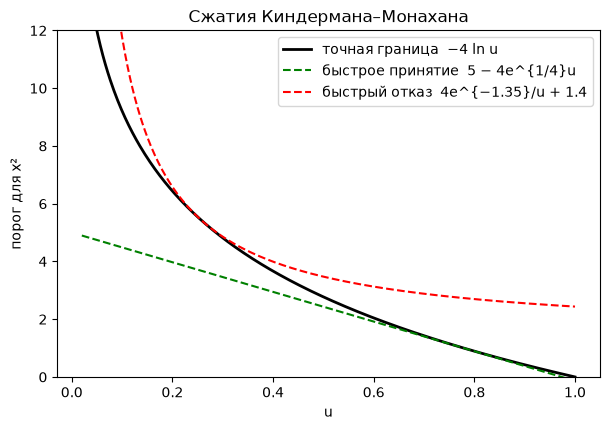

In [16]:
u_grid, x_grid = np.meshgrid(np.linspace(1e-4, 1, 1500), np.linspace(-6, 6, 1500))
x2_grid = x_grid ** 2

exact = x2_grid <= -4 * np.log(u_grid)
qa = x2_grid <= 5 - A_ACCEPT * u_grid
qr = x2_grid >= B_REJECT / u_grid + 1.4

print("Быстрое принятие там, где точная проверка отклоняет:", np.sum(qa & ~exact), "точек")
print("Быстрый отказ там, где точная проверка принимает:  ", np.sum(qr & exact), "точек")

# Картинка: граница -4 ln u и две границы-сжатия
u_line = np.linspace(0.02, 1, 400)
plt.figure(figsize=(7, 4.5))
plt.plot(u_line, -4 * np.log(u_line), "k", lw=2, label="точная граница  −4 ln u")
plt.plot(u_line, 5 - A_ACCEPT * u_line, "g--", label="быстрое принятие  5 − 4e^{1/4}u")
plt.plot(u_line, B_REJECT / u_line + 1.4, "r--", label="быстрый отказ  4e^{−1.35}/u + 1.4")
plt.ylim(0, 12)
plt.xlabel("u"); plt.ylabel("порог для x²")
plt.title("Сжатия Киндермана–Монахана")
plt.legend()
plt.show()

Зелёная линия везде ниже чёрной, красная - везде выше: сжатия никогда не ошибаются, а логарифм нужен только в узкой полосе между ними.
0 ложных срабатываний по результатам теста и график подтверждают, что границы сжатий Киндермана-Монахана строго огибают точную границу. Это гарантирует, что отказ от использования логарифма не исказит распределение и в целом сработает математически корректно.

**Тест 3. Доля принятия, расход равномерных чисел и частота вычисления логарифма.**
$P(\text{принятия}) = \sqrt{\pi e}/4 \approx 0.7306$, равномерных на одно число $\approx 2.737$.

In [17]:
info = {}
z_rou = rou_v2(n_big, UniformSource(seed=2026), stats_out=info)

# Доля принятия = принятые точки / все точки; каждая точка = 2 равномерных, принятая = 1 нормальное
acceptance_rou = info["accepted"] / info["attempts"]
uniform_per_normal_rou = 2 * info["attempts"] / info["accepted"]
print(f"Доля принятых точек:     эмпирически {acceptance_rou:.4f}, теория √(πe)/4 = {np.sqrt(np.pi * np.e) / 4:.4f}")
print(f"Равномерных на 1 норм.:  эмпирически {uniform_per_normal_rou:.4f}, теория 8/√(πe) = {8 / np.sqrt(np.pi * np.e):.4f}")
print(f"Логарифм понадобился в {info['logs'] / info['attempts']:.1%} попыток "
      f"(без сжатий было бы 100%)")

Доля принятых точек:     эмпирически 0.7310, теория √(πe)/4 = 0.7306
Равномерных на 1 норм.:  эмпирически 2.7361, теория 8/√(πe) = 2.7376
Логарифм понадобился в 17.0% попыток (без сжатий было бы 100%)


В 83% случаев алгоритм обходится без самой времязатратной операции (логарифмирования), оперируя только сложением и умножением. Такая экономия обеспечивает адекватную скорость его работы.

**Тест 4. Датчик выдаёт N(0,1): сравнение с теоретическими значениями на 1 000 000 чисел.**

In [18]:
check_standard_normal(z_rou, "Метод отношений")

=== Метод отношений: сравнение с N(0,1), n = 1000000 ===
               датчик  теория N(0,1)  разница
mean           0.0007         0.0000   0.0007
std            1.0002         1.0000   0.0002
skew          -0.0004         0.0000  -0.0004
kurt (excess) -0.0023         0.0000  -0.0023
q05           -1.6448        -1.6449   0.0001
q25           -0.6730        -0.6745   0.0015
median        -0.0003         0.0000  -0.0003
q75            0.6761         0.6745   0.0016
q95            1.6443         1.6449  -0.0005

Колмогоров:   D = 0.0008, p = 0.559
Шапиро–Уилк:  W = 0.9996, p = 0.408


(np.float64(0.5586492445338925), np.float64(0.4077043483366154))

Как результаты статистического анализа, так и значения p по результатам прохождения критериев Колмогорова-Смирнова и Шапиро-Уилка показывают, что сгенерированная выборка соответствует нормальному распределению, что означает, что метод был реализован корректно.


**Тест 5. Последовательные значения независимы.** В методе отношений каждое число получается из своей пары $(U_1, U_2)$, поэтому соседние значения не должны быть связаны. Проверяем автокорреляцию для лагов 1–5.

In [19]:
for lag in range(1, 6):
    r = np.corrcoef(z_rou[:-lag], z_rou[lag:])[0, 1]
    print(f"Автокорреляция, лаг {lag}: {r:+.5f}")
print(f"\nГраница «шума» ±2/√n = ±{2 / np.sqrt(n_big):.5f}")

Автокорреляция, лаг 1: -0.00155
Автокорреляция, лаг 2: -0.00078
Автокорреляция, лаг 3: +0.00016
Автокорреляция, лаг 4: -0.00040
Автокорреляция, лаг 5: -0.00156

Граница «шума» ±2/√n = ±0.00200


Поскольку в методе Киндермана-Монахана каждое новое число генерируется из новой пары равномерных величин, соседние значения не связаны. Тест это подтвердил: оказалось, что значения автокорреляции для лагов 1-5 статистически незначимы и находятся в пределах ±0.00200.

**Тест 6. Сравнение датчика с реальными X1.**

               X1 (реальные)  Метод отношений  разница, %
n                   1960.000         1960.000       0.000
mean                3550.865         3542.915      -0.224
std                  428.902          431.562       0.620
skew                   0.047           -0.118    -347.814
kurt (excess)         -0.356            0.043     112.160
q05                 2838.950         2820.697      -0.643
q25                 3247.000         3258.037       0.340
median              3556.000         3541.781      -0.400
q75                 3862.000         3839.136      -0.592
q95                 4237.000         4233.906      -0.073

Двухвыборочный Колмогоров–Смирнов: D = 0.0219, p = 0.733


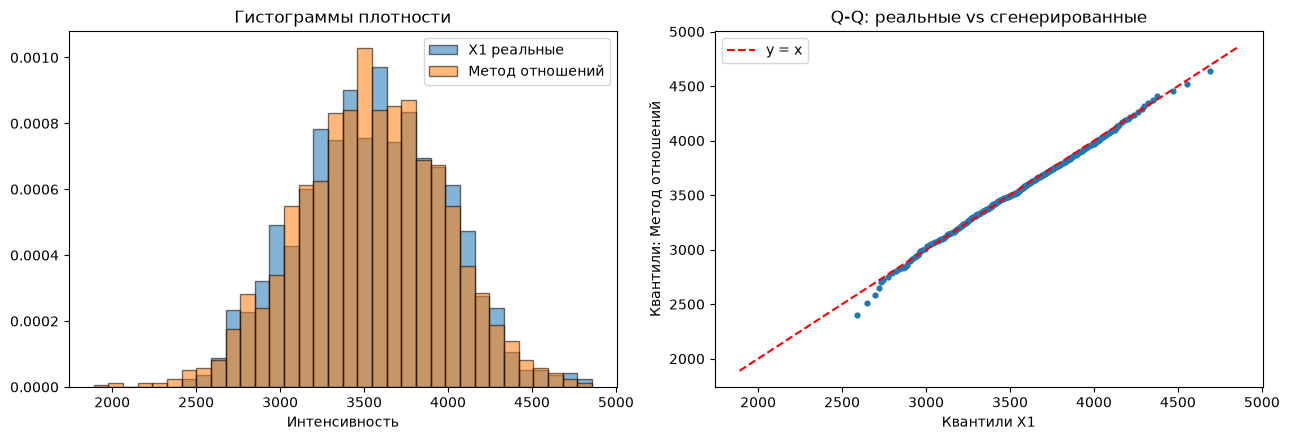

In [20]:
gen_rou = rou_normal(N_REAL, mu=mu_hat, sigma=sigma_hat, seed=42)
p_ks2_rou = compare_with_real(X1, gen_rou, "Метод отношений")
plot_vs_real(X1, gen_rou, "Метод отношений")

Итак, метод отношений корректно воспроизвёл реальное распределение измерений: критерий Колмогорова-Смирнова дал значение значительно больше 0.05, квантили и стандартное отклонение тоже совпали, ура.

### Выводы

* Пошаговая и векторная реализации совпадают
* Сжатия проверены на сетке: ошибок выявлено не было, значит, сжатия ускоряют алгоритм, не меняя распределения. Логарифм вычисляется лишь примерно в каждой шестой попытке (≈17%).
* Доля принятия и расход равномерных чисел совпали с теоретическими $\sqrt{\pi e}/4$ и $8/\sqrt{\pi e}$.
* На миллионе чисел метрики совпадают с N(0,1), критерии нормальности при этом отвергнуты не были
* Сравнение с X1 даёт ту же картину, что и у полярного метода: центр и разброс совпадают, небольшие отличия возможны в эксцессе и хвостах из-за того, что сами данные чуть «плосковершиннее» нормального закона.

## Итоговая таблица метрик

Сравним реальные измерения X1 с результатами обоих генераторов. Для каждого случая берём по 1960 значений, чтобы сравнение было одинаковым. В первой таблице смотрим статистики распределения, во второй-особенности самих алгоритмов, сколько случайных чисел они тратят, как часто отбрасывают точки и сколько времени работают.

In [21]:

summary = pd.DataFrame({
    "X1 (реальные)": metrics(X1),
    "Полярный метод": metrics(gen_polar),
    "Метод отношений": metrics(gen_rou),
}).round(3)
summary.loc["KS 2-выб. p-value vs X1"] = ["—", round(p_ks2_polar, 3), round(p_ks2_rou, 3)]
print("Метрики распределения:")
display(summary) if "display" in globals() else print(summary)

# Время генерации 10^6 чисел
def timeit(fn, repeats=5):
    best = np.inf
    for i in range(repeats):
        t0 = time.perf_counter(); fn(); best = min(best, time.perf_counter() - t0)
    return best

t_polar = timeit(lambda: polar_v2(n_big, UniformSource(1)))
t_rou = timeit(lambda: rou_v2(n_big, UniformSource(1)))
t_numpy = timeit(lambda: np.random.Generator(np.random.MT19937(1)).standard_normal(n_big))

algo = pd.DataFrame({
    "Полярный метод": {
        "статья": "Marsaglia, Bray, 1964",
        "P(принятия) теория": round(np.pi / 4, 4),
        "P(принятия) эмпир.": round(acceptance, 4),
        "U(0,1) на 1 число": round(uniform_per_normal, 3),
        "чисел за 1 успех": 2,
        "тяжёлые функции": "ln, sqrt — всегда",
        "время 10^6, с": round(t_polar, 3),
    },
    "Метод отношений": {
        "статья": "Kinderman, Monahan, 1977",
        "P(принятия) теория": round(np.sqrt(np.pi * np.e) / 4, 4),
        "P(принятия) эмпир.": round(acceptance_rou, 4),
        "U(0,1) на 1 число": round(uniform_per_normal_rou, 3),
        "чисел за 1 успех": 1,
        "тяжёлые функции": f"ln — в {info['logs'] / info['attempts']:.0%} попыток",
        "время 10^6, с": round(t_rou, 3),
    },
})
print("\nХарактеристики алгоритмов (для сравнения numpy.standard_normal: "
      f"{t_numpy:.3f} c на 10^6 — это метод зиккурата на C):")
display(algo) if "display" in globals() else print(algo)

Метрики распределения:
                        X1 (реальные)  Полярный метод  Метод отношений
n                              1960.0        1960.000         1960.000
mean                         3550.865        3561.212         3542.915
std                           428.902         427.372          431.562
skew                            0.047          -0.018           -0.118
kurt (excess)                  -0.356          -0.037            0.043
q05                           2838.95        2847.746         2820.697
q25                            3247.0        3278.453         3258.037
median                         3556.0        3558.762         3541.781
q75                            3862.0        3858.299         3839.136
q95                            4237.0        4252.838         4233.906
KS 2-выб. p-value vs X1             —           0.423            0.733

Характеристики алгоритмов (для сравнения numpy.standard_normal: 0.012 c на 10^6 — это метод зиккурата на C):
               

Сравним статистические характеристики реальных и сгенерированных данных. Видим, что оба метода дают близкие значения среднего, медианы и стандартного отклонения. При этом по асимметрии и эксцессу есть небольшие расхождения, особенно с реальным распределением.

Проверка критерием Колмогорова–Смирнова также не выявила статистически значимых различий: для полярного метода p = 0,423, для метода отношений p = 0,733. Оба значения больше 0,05, поэтому оснований отвергать гипотезу об одинаковом распределении нет.

По эффективности полярный метод оказался лучше: он генерирует миллион чисел за 0,048 с против 0,072 с у метода отношений. Кроме того, у него выше вероятность принятия и меньше расход равномерных случайных чисел.

Таким образом, оба метода подходят для приближённого воспроизведения распределения X1, однако в нашей реализации полярный метод показал более высокую скорость работы.

## Автотесты генератора

Соберём основные проверки в автотесты, чтобы после изменений кода не проверять каждый результат вручную. Смотрим, повторяются ли числа при одинаковом seed, совпадают ли две версии методов и нет ли некорректных значений. Затем проверяем статистики, нормальность и перенос генератора к параметрам X1. Отдельно тестируем быстрые условия принятия и отказа во втором методе.

In [24]:
def run_autotests():
    n = 200_000
    generators = {"polar": (polar_v1, polar_v2), "ratio-of-uniforms": (rou_v1, rou_v2)}
    for name, (v1, v2) in generators.items():
        # 1. воспроизводимость: одинаковый seed -> одинаковые числа
        a = v2(1000, UniformSource(5)); b = v2(1000, UniformSource(5))
        assert np.array_equal(a, b), f"{name}: нет воспроизводимости по seed"

        # 2. разные seed -> разные числа
        c = v2(1000, UniformSource(6))
        assert not np.array_equal(a, c), f"{name}: разные seed дают одно и то же"

        # 3. пошаговая версия (по статье) == векторная
        assert np.allclose(v1(1000, UniformSource(9)), v2(1000, UniformSource(9))), \
            f"{name}: v1 и v2 расходятся"

        # 4. ровно n чисел, все конечные
        z = v2(n, UniformSource(11))
        assert len(z) == n and np.all(np.isfinite(z)), f"{name}: неверная длина или NaN/inf"

        # 5. моменты N(0,1)
        assert abs(z.mean()) < 0.01, f"{name}: среднее {z.mean():.4f}"
        assert abs(z.std() - 1) < 0.01, f"{name}: std {z.std():.4f}"
        assert abs(stats.skew(z)) < 0.03, f"{name}: асимметрия {stats.skew(z):.4f}"
        assert abs(stats.kurtosis(z)) < 0.06, f"{name}: эксцесс {stats.kurtosis(z):.4f}"

        # 6. критерий Колмогорова против N(0,1)
        p = stats.kstest(z, "norm").pvalue
        assert p > 0.001, f"{name}: Колмогоров отверг N(0,1), p = {p:.2e}"

        # 7. преобразование к N(mu, sigma)
        x = mu_hat + sigma_hat * z
        assert abs(x.mean() - mu_hat) < 0.01 * sigma_hat, f"{name}: сдвиг на mu не работает"

        print(f"[OK] {name}: все 7 проверок пройдены")

    # 8. сжатия метода отношений никогда не противоречат точной проверке
    assert not np.any(qa & ~exact) and not np.any(qr & exact), "squeeze-границы неверны"
    print("[OK] сжатия Киндермана–Монахана корректны")


run_autotests()

[OK] polar: все 7 проверок пройдены
[OK] ratio-of-uniforms: все 7 проверок пройдены
[OK] сжатия Киндермана–Монахана корректны


### Вывод по автотестам
Провели автоматическое тестирование обоих генераторов. Все 7 проверок для каждого метода завершены. Дополнительно проверили условия сжатия в алгоритме Киндермана-Монахана, ошибок нет.
Таким образом, оба генератора корректно работают и позволяют получать случайные числа с заданными статистическими характеристиками. 

## Вывод по спринту 2

По величине X1 (интенсивность на 500.33 см⁻¹), для которой в спринте 1 была принята гипотеза о нормальности, построены два датчика нормальных случайных чисел по первоисточникам: полярный метод Марсальи-Брэя (1964) и метод отношений равномерных величин Киндермана-Монахана (1977). Оба используют вихрь Мерсенна как источник U(0,1), генерируют N(0,1) и переводятся в масштаб данных преобразованием X = μ̂ + σ̂Z.

Для каждого датчика: выведено математическое обоснование, реализованы пошаговая (по тексту статьи) и векторная версии с проверкой их совпадения, эмпирически подтверждены теоретические доля принятия и расход равномерных чисел, проверено соответствие N(0,1) на 10⁶ значений, проверена независимость, проведено сравнение метрик с реальными X1. Ключевые проверки вынесены в автотесты.

## Литература

**Первоисточники генераторов**

1. Marsaglia G., Bray T. A. A Convenient Method for Generating Normal Variables // SIAM Review. 1964. Vol. 6, № 3. P. 260–264. — doi:10.1137/1006063. *(датчик 1)*
2. Kinderman A. J., Monahan J. F. Computer Generation of Random Variables Using the Ratio of Uniform Deviates // ACM Transactions on Mathematical Software. 1977. Vol. 3, № 3. P. 257–260. — doi:10.1145/355744.355750. *(датчик 2)*

**Сопутствующие статьи**

3. Box G. E. P., Muller M. E. A Note on the Generation of Random Normal Deviates // The Annals of Mathematical Statistics. 1958. Vol. 29, № 2. P. 610–611. — doi:10.1214/aoms/1177706645. *(предшественник полярного метода)*
4. Matsumoto M., Nishimura T. Mersenne Twister: a 623-dimensionally equidistributed uniform pseudo-random number generator // ACM Transactions on Modeling and Computer Simulation. 1998. Vol. 8, № 1. P. 3–30. — doi:10.1145/272991.272995. *(базовый датчик U(0,1))*
5. Leva J. L. A Fast Normal Random Number Generator // ACM Transactions on Mathematical Software. 1992. Vol. 18, № 4. P. 449–453. — doi:10.1145/138351.138364. *(улучшение метода отношений: более точные квадратичные сжатия)*
6. Marsaglia G., MacLaren M. D., Bray T. A. A Fast Procedure for Generating Normal Random Variables // Communications of the ACM. 1964. Vol. 7, № 1. P. 4–10. — doi:10.1145/363872.363883. *(метод «прямоугольник–клин–хвост» из списка задания)*

**Книги**

7. Кнут Д. Э. Искусство программирования. Т. 2: Получисленные алгоритмы. 3-е изд. — М.: Вильямс, 2000. — Разд. 3.4.1 (Алгоритм P — полярный метод, Алгоритм R — метод отношений).
8. Devroye L. Non-Uniform Random Variate Generation. — New York: Springer-Verlag, 1986. — Гл. IV.7 (ratio-of-uniforms), гл. V.4 (полярный метод).
9. Соболь И. М. Численные методы Монте-Карло. — М.: Наука, 1973.
10. Ермаков С. М. Метод Монте-Карло и смежные вопросы. 2-е изд. — М.: Наука, 1975.